In [2]:
import numpy as np 
import pandas as pd
from tqdm import tqdm 
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
import matplotlib.pyplot as plt
import statsmodels.api as sn
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from pmdarima.arima import auto_arima

In [5]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\monthly-milk-production-pounds-p.csv")
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


In [7]:
y=df.Milk
y_train=y[:-12]
y_test=y[-12:]

In [8]:
model=ARIMA(y_train,order=(2,1,1))
model_fit=model.fit()
print('Coefficient: %s' % model_fit.params)
predictions=model_fit.predict(start=len(y_train),end=len(y_train)+len(y_test)-1)
error=root_mean_squared_error(y_test,predictions)
error

Coefficient: ar.L1       -0.087896
ar.L2        0.272233
ma.L1        0.120660
sigma2    1882.401213
dtype: float64


72.86259402377816

In [9]:
model=auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)
forecast=model.predict(n_periods=len(y_test))
forecast=pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms=root_mean_squared_error(y_test,forecast)
print('TEST RMSE %:',rms)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1593.690, Time=0.84 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1624.299, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1626.095, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1626.164, Time=0.14 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1622.458, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1604.395, Time=0.44 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1618.644, Time=0.32 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.91 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=1572.500, Time=1.18 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.78 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.30 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.26 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=1562.133, Time=1.55 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=inf, Time=1.36 sec
 ARIMA(1,1,5)(0,0,0)[0] intercept   : AIC=inf, Time=1.52 s

### Sarima 

In [13]:
model=auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True,m=12,seasonal=True)
forecast=model.predict(n_periods=len(y_test))
forecast=pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms=root_mean_squared_error(y_test,forecast)
print('TEST RMSE %:',rms)

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=1000.136, Time=2.35 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=1218.095, Time=0.03 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=1015.855, Time=0.47 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=1104.312, Time=0.63 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=1349.320, Time=0.04 sec
 ARIMA(2,0,2)(0,1,1)[12] intercept   : AIC=998.169, Time=1.60 sec
 ARIMA(2,0,2)(0,1,0)[12] intercept   : AIC=1038.230, Time=0.50 sec
 ARIMA(2,0,2)(0,1,2)[12] intercept   : AIC=1000.125, Time=3.34 sec
 ARIMA(2,0,2)(1,1,0)[12] intercept   : AIC=1012.395, Time=1.77 sec
 ARIMA(2,0,2)(1,1,2)[12] intercept   : AIC=inf, Time=6.28 sec
 ARIMA(1,0,2)(0,1,1)[12] intercept   : AIC=996.457, Time=1.25 sec
 ARIMA(1,0,2)(0,1,0)[12] intercept   : AIC=1036.989, Time=0.28 sec
 ARIMA(1,0,2)(1,1,1)[12] intercept   : AIC=998.423, Time=1.62 sec
 ARIMA(1,0,2)(0,1,2)[12] intercept   : AIC=998.411, Time=2.64 sec
 ARIMA(1,0,2)(1,1,0)[12] int

In [14]:
forecast

,Prediction
156,838.789629
157,797.309975
158,902.001624
159,918.983885
160,982.162885
161,957.974560
162,916.613383
163,877.743652
164,828.807096
165,832.279162


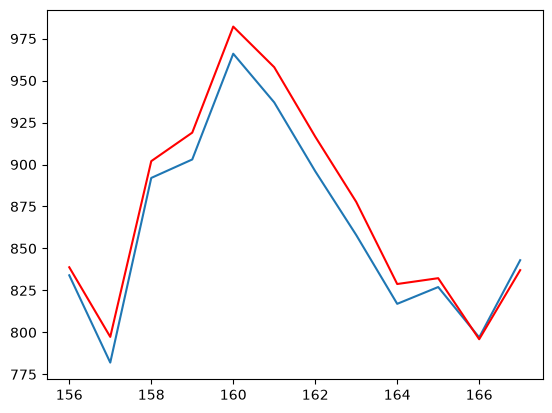

In [15]:
plt.plot(y_test)
plt.plot(forecast,color='r')
plt.show()